# 01 - Exploratory Data Analysis

## Project: Improving Basket Trading Using Bayesian Optimization

### Objective

This notebook performs an exploratory analysis of five U.S. sector ETFs as the first stage of a quantitative basket trading research project.

The objective is to understand the structure, quality, historical behavior and risk-return characteristics of the selected assets before conducting stationarity and cointegration tests.

### Selected Assets

- **XLK:** Technology Select Sector SPDR Fund
- **XLF:** Financial Select Sector SPDR Fund
- **XLE:** Energy Select Sector SPDR Fund
- **XLI:** Industrial Select Sector SPDR Fund
- **XLP:** Consumer Staples Select Sector SPDR Fund

### Dataset

- **Source:** Yahoo Finance, downloaded using `yfinance`
- **Frequency:** Daily trading observations
- **Period:** January 2015 to October 2026
- **Observations:** 2,972
- **Assets:** 5

### Analysis Roadmap

1. Load and inspect historical ETF prices.
2. Assess data quality and missing values.
3. Explore historical price behavior.
4. Normalize prices to a common base of 100.
5. Calculate cumulative and daily returns.
6. Analyze basic risk-return statistics.
7. Visualize historical performance.

### Next Steps

The results of this exploratory analysis will support subsequent stationarity, correlation, and cointegration analysis, followed by Bayesian Optimization of basket trading strategies.

In [5]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Python executable:", sys.executable)
print("Pandas version:", pd.__version__)
print("Notebook working directory:", Path.cwd())

Python executable: /Users/ady/Proyectos/bayesian-basket-trading/.venv/bin/python
Pandas version: 3.1.1
Notebook working directory: /Users/ady/Proyectos/bayesian-basket-trading/notebooks


## 1. Data Loading and Initial Inspection

In this section, we load the historical ETF price dataset and inspect its structure.

We will verify the number of observations, available assets, date range, and data types before proceeding with the exploratory analysis.

In [6]:
# Define project paths
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "etf_prices.csv"

# Load historical ETF prices
prices = pd.read_csv(
    DATA_PATH,
    index_col="Date",
    parse_dates=True
)

# Inspect the dataset
print("Dataset shape:", prices.shape)

print("\nFirst date:", prices.index.min())
print("Last date:", prices.index.max())

print("\nFirst five observations:")
display(prices.head())

Dataset shape: (2972, 5)

First date: 2015-01-02 00:00:00
Last date: 2026-10-27 00:00:00

First five observations:


,XLK,XLF,XLE,XLI,XLP
Date,,,,,
2015-01-02,18.041674,16.160784,25.215256,45.974426,35.385529
2015-01-05,17.766275,15.820963,24.172153,44.900524,35.136688
2015-01-06,17.552063,15.579174,23.817047,44.347294,35.092777
2015-01-07,17.700697,15.742550,23.867773,44.680851,35.692909
2015-01-08,18.089771,15.977813,24.403605,45.575783,36.234489


## 2. Data Quality Assessment

Before analyzing financial time series, we assess the dataset for missing values, duplicated dates and incorrect data types.

These checks help ensure that subsequent return calculations and statistical analyses are based on consistent and reliable observations.

In [7]:
# 1. Check dataset dimensions
print("Dataset shape:")
print(prices.shape)

# 2. Check data types
print("\nData types:")
print(prices.dtypes)

# 3. Check missing values
print("\nMissing values per ETF:")
print(prices.isna().sum())

# 4. Check duplicated dates
print("\nDuplicated dates:")
print(prices.index.duplicated().sum())

# 5. Check chronological order
print("\nDates sorted chronologically:")
print(prices.index.is_monotonic_increasing)

Dataset shape:
(2972, 5)

Data types:
XLK    float64
XLF    float64
XLE    float64
XLI    float64
XLP    float64
dtype: object

Missing values per ETF:
XLK    0
XLF    0
XLE    0
XLI    0
XLP    0
dtype: int64

Duplicated dates:
0

Dates sorted chronologically:
True


### Data Quality Findings

The dataset contains 2,972 daily observations for each of the five sector ETFs, resulting in **14,860 price values**.

All price columns are stored as `float64`. No missing values or duplicated dates were detected and the date index is chronologically ordered.

The dataset passed the initial structural data quality checks and is ready for further exploratory analysis.

## 3. Descriptive Statistics of Historical Prices

This section summarizes the distribution of historical ETF prices using descriptive statistics.

We examine the mean, standard deviation, minimum, maximum and quartiles to understand the historical price levels and dispersion of each asset.

These statistics describe price levels and should not be interpreted directly as investment returns or return volatility.

In [8]:
# Calculate descriptive statistics
price_stats = prices.describe()

# Display summary statistics
display(price_stats.round(2))

,XLK,XLF,XLE,XLI,XLP
count,2972.00,2972.00,2972.00,2972.00,2972.00
mean,65.11,30.21,30.01,87.81,56.98
std,44.07,11.97,11.65,37.01,15.17
min,16.62,13.10,9.12,39.89,33.86
25%,29.17,20.98,22.07,59.30,42.58
50%,58.37,27.09,24.73,79.23,56.02
75%,87.69,36.46,39.31,104.08,68.62
max,202.00,58.35,69.64,186.01,89.99


## 4. Historical ETF Price Visualization

We visualize the historical price series of the five sector ETFs to examine long-term trends, major market movements and differences in price levels.

Since the ETFs have different price scales, this initial visualization should not be used to compare investment performance directly. A normalized price comparison will be performed in the next section.

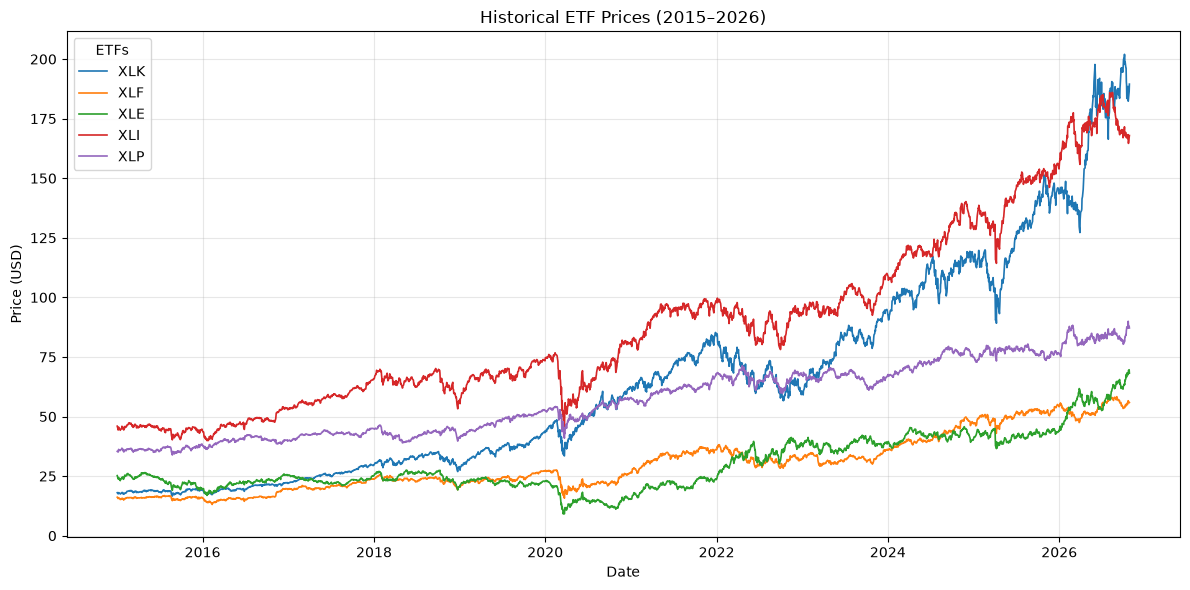

In [9]:
# Plot historical ETF prices
plt.figure(figsize=(12, 6))

for ticker in prices.columns:
    plt.plot(
        prices.index,
        prices[ticker],
        label=ticker,
        linewidth=1.2
    )

plt.title("Historical ETF Prices (2015–2026)")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend(title="ETFs")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Normalized ETF Price Comparison

To compare the historical performance of ETFs with different initial price levels, we normalize all price series to a common starting value of 100.

This transformation allows us to compare cumulative percentage changes over the observation period.

A normalized value of 150 represents a 50% increase relative to the initial price, while a value of 80 represents a 20% decrease.

Normalized prices are useful for performance comparisons but do not represent daily returns.

,XLK,XLF,XLE,XLI,XLP
Date,,,,,
2015-01-02,100.000000,100.000000,100.000000,100.000000,100.000000
2015-01-05,98.473544,97.897250,95.863210,97.664132,99.296774
2015-01-06,97.286224,96.401104,94.454910,96.460788,99.172681
2015-01-07,98.110061,97.412045,94.656082,97.186316,100.868662
2015-01-08,100.266592,98.867809,96.781110,99.132902,102.399175


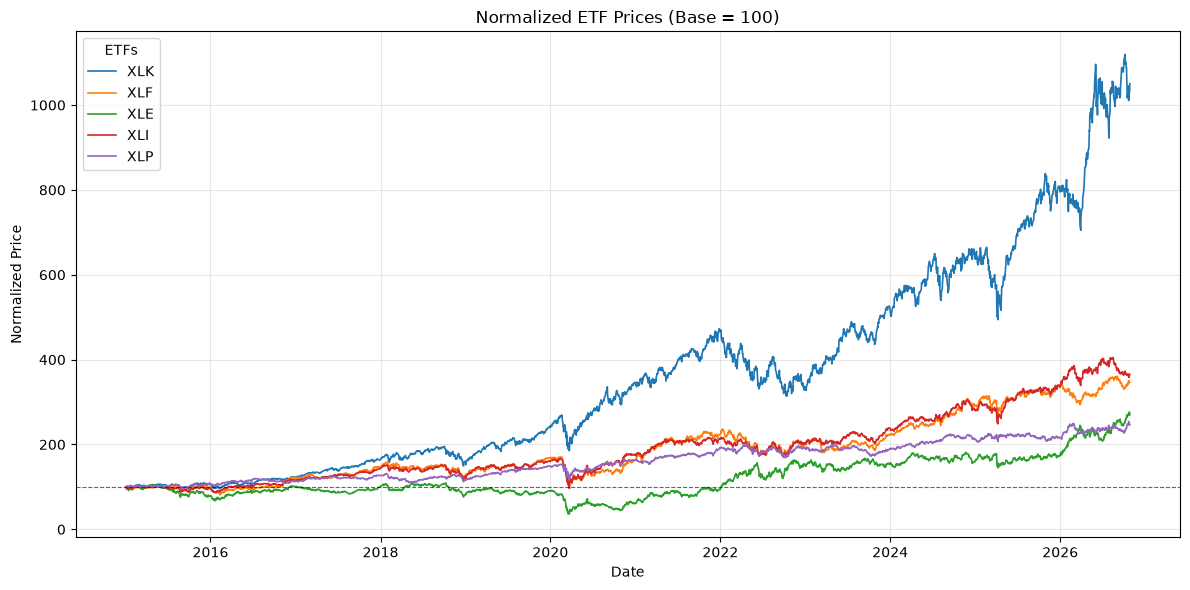

In [10]:
# Normalize all ETF prices to a base of 100
normalized_prices = prices.div(prices.iloc[0]).mul(100)

# Verify the first observations
display(normalized_prices.head())

# Plot normalized ETF prices
plt.figure(figsize=(12, 6))

for ticker in normalized_prices.columns:
    plt.plot(
        normalized_prices.index,
        normalized_prices[ticker],
        label=ticker,
        linewidth=1.2
    )

plt.axhline(
    y=100,
    color="black",
    linestyle="--",
    linewidth=0.8,
    alpha=0.6
)

plt.title("Normalized ETF Prices (Base = 100)")
plt.xlabel("Date")
plt.ylabel("Normalized Price")
plt.legend(title="ETFs")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Cumulative Returns Analysis

We calculate the cumulative percentage return of each ETF over the full observation period.

Cumulative returns measure the total percentage change between the initial and final observed prices.

This allows us to rank the ETFs by historical performance without relying solely on visual comparisons.

The calculation is based on the price series available in the dataset and does not account for transaction costs.

In [11]:
# Calculate cumulative returns (%)
cumulative_returns = (prices.iloc[-1] / prices.iloc[0] - 1) * 100

# Rank ETFs from highest to lowest return
cumulative_returns = cumulative_returns.sort_values(ascending=False)

# Display results
print("Cumulative Returns (%):")
display(cumulative_returns.round(2))

Cumulative Returns (%):


XLK    950.29
XLI    265.25
XLF    245.78
XLE    170.51
XLP    146.29
dtype: float64

## 7. Daily Returns Analysis

Daily simple returns measure the percentage change in an ETF's price between consecutive trading observations.

Unlike price levels, returns allow us to compare relative daily movements across assets with different price scales.

In this section, we calculate daily returns and summarize their average values and standard deviations. The standard deviation of daily returns provides a historical measure of return volatility.

In [12]:
# Calculate daily simple returns
returns = prices.pct_change().dropna()

# Display dataset dimensions
print("Prices shape:", prices.shape)
print("Returns shape:", returns.shape)

# Display first five daily returns
print("\nFirst five daily returns:")
display(returns.head())

# Calculate mean daily returns
mean_returns = returns.mean() * 100

# Calculate daily volatility
daily_volatility = returns.std() * 100

# Create a summary table
risk_return_summary = pd.DataFrame({
    "Mean Daily Return (%)": mean_returns,
    "Daily Volatility (%)": daily_volatility
})

display(risk_return_summary.round(4))

Prices shape: (2972, 5)
Returns shape: (2971, 5)

First five daily returns:


,XLK,XLF,XLE,XLI,XLP
Date,,,,,
2015-01-05,-0.015265,-0.021027,-0.041368,-0.023359,-0.007032
2015-01-06,-0.012057,-0.015283,-0.014691,-0.012321,-0.001250
2015-01-07,0.008468,0.010487,0.002130,0.007521,0.017101
2015-01-08,0.021981,0.014944,0.022450,0.020029,0.015173
2015-01-09,-0.003142,-0.013498,-0.007926,-0.010711,-0.008079


,Mean Daily Return (%),Daily Volatility (%)
XLK,0.0906,1.5135
XLF,0.0510,1.3550
XLE,0.0503,1.8257
XLI,0.0511,1.2262
XLP,0.0346,0.9238


## 8. Daily Returns Visualization

We visualize daily ETF returns to examine fluctuations around zero, extreme market movements and periods of increased volatility.

This analysis provides an initial qualitative assessment of the time-series behavior of financial returns.

Visual inspection alone cannot establish stationarity. Formal statistical tests will be conducted in the subsequent notebook.

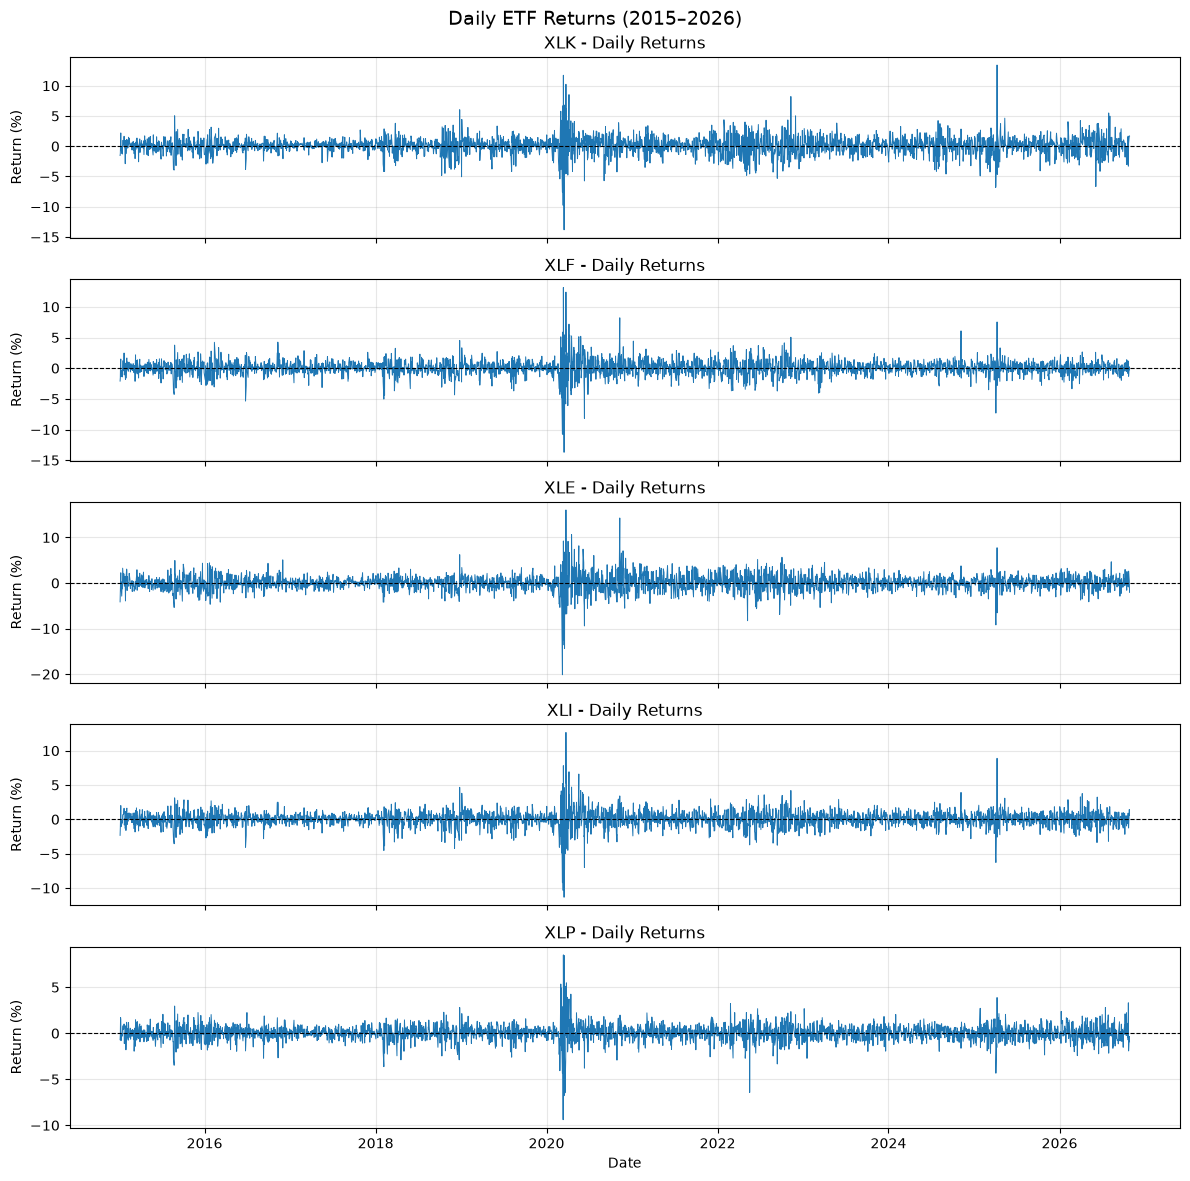

In [13]:
# Plot daily returns for all five ETFs
fig, axes = plt.subplots(
    nrows=5,
    ncols=1,
    figsize=(12, 12),
    sharex=True
)

for ax, ticker in zip(axes, returns.columns):

    ax.plot(
        returns.index,
        returns[ticker] * 100,
        linewidth=0.7
    )

    ax.axhline(
        y=0,
        color="black",
        linestyle="--",
        linewidth=0.8
    )

    ax.set_title(f"{ticker} - Daily Returns")
    ax.set_ylabel("Return (%)")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Date")

fig.suptitle(
    "Daily ETF Returns (2015–2026)",
    fontsize=14
)

plt.tight_layout()
plt.show()

## 9. Key Findings and Conclusions

The exploratory analysis of five U.S. sector ETFs from January 2015 to October 2026 provides the following findings:

**1. Data Quality**
The dataset contains 2,972 daily price observations for each of the five ETFs. No missing values or duplicated dates were identified, and all price columns have numeric data types.

**2. Historical Performance**
XLK achieved the highest cumulative return (950.29%), followed by XLI (265.25%), XLF (245.78%), XLE (170.51%), and XLP (146.29%).

**3. Risk and Return**
XLK recorded the highest average daily return (0.0906%), while XLE exhibited the highest daily return volatility (1.8257%). XLP had the lowest daily volatility (0.9238%).

These findings highlight the importance of distinguishing historical performance from investment risk.

**4. Time-Series Behavior**
ETF price levels exhibit long-term trends, while daily returns fluctuate around levels close to zero.

Periods of increased market volatility are visible, particularly around 2020. These patterns motivate further investigation into stationarity and time-varying volatility.

**5. Limitations**
The analysis is descriptive and does not establish stationarity, cointegration, or future predictive performance. Transaction costs and portfolio constraints have not yet been incorporated.


## Next Research Stage
The next notebook, `02_stationarity_analysis.ipynb`, will investigate the statistical properties of ETF price and return series.

The analysis will introduce the Augmented Dickey-Fuller (ADF) and KPSS tests before progressing to correlation and cointegration analysis.